In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [83]:
data = pd.read_excel('featrue3.xlsx')

In [85]:
data.columns

Index(['Unnamed: 0', 'T_e_number', 'T_electronegetivity', 'T_ionicradii(T)',
       'T_ionicradii(O)', 'T_valencee', 'T_cutoffraii', 'CF in zinc(O)',
       'CF in zinc(M)', 'CF in rock(O)', 'CF in rock(M)', 'O_e_number',
       'O_electronegetivity', 'O_ionicradii(T)', 'O_ionicradii(O)',
       'O_valencee', 'O_cutoffraii', 'CF in zinc(O).1', 'CF in zinc(M).1',
       'CF in rock(O).1', 'CF in rock(M).1', 'max', 'delta'],
      dtype='object')

In [87]:
X = data[['T_e_number', 'T_electronegetivity', 'T_ionicradii(T)',
       'T_ionicradii(O)', 'T_valencee', 'T_cutoffraii', 'CF in zinc(O)',
       'CF in zinc(M)', 'CF in rock(O)', 'CF in rock(M)', 'O_e_number',
       'O_electronegetivity', 'O_ionicradii(T)', 'O_ionicradii(O)',
       'O_valencee', 'O_cutoffraii', 'CF in zinc(O).1', 'CF in zinc(M).1',
       'CF in rock(O).1', 'CF in rock(M).1']]
Y1 = data['max']

In [89]:
print(X.shape)
print(Y1.shape)

(157, 20)
(157,)


In [91]:
import xgboost as xgb
model_xgb = xgb.XGBRegressor(learning_rate=0.25, n_estimators=500)

In [93]:
model_xgb.fit(X, Y1)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.25, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=None, num_parallel_tree=None, ...)

In [95]:
model_xgb.feature_importances_

array([0.00958502, 0.12940687, 0.01292723, 0.01469616, 0.        ,
       0.        , 0.00509932, 0.00876756, 0.00302205, 0.04598201,
       0.03470346, 0.02306684, 0.01228447, 0.02500306, 0.6294507 ,
       0.        , 0.01546781, 0.00790932, 0.01601886, 0.00660931],
      dtype=float32)

In [97]:
#shap
import shap

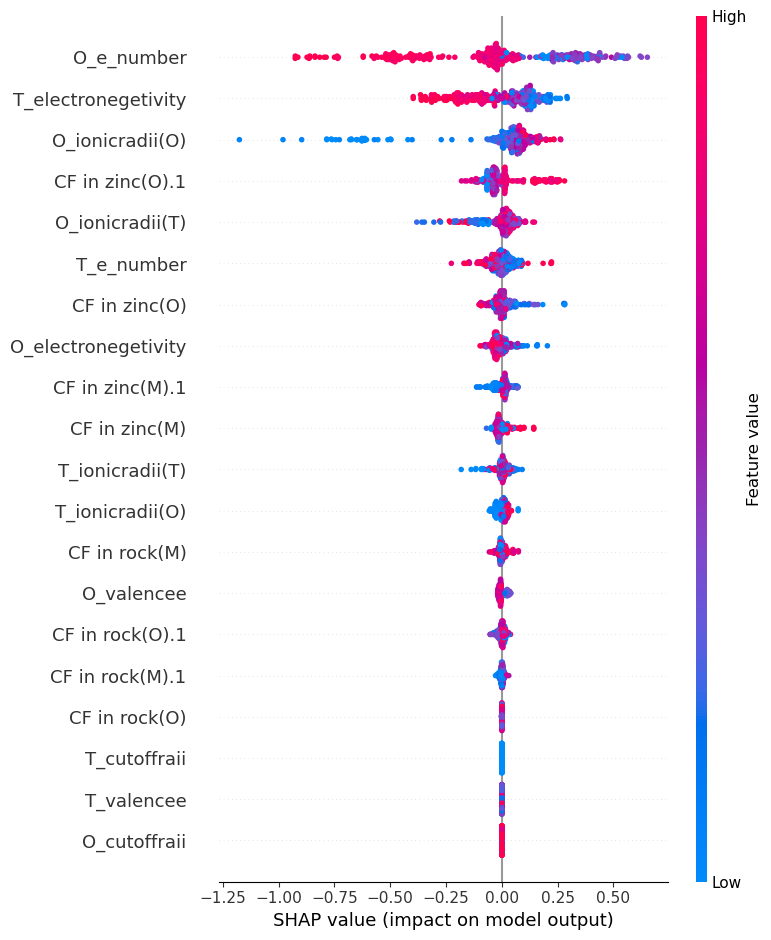

In [73]:
shap.summary_plot(SHAP_value.values, X, show=False)
plt.savefig("shap_summary_highres.png", dpi=600, bbox_inches='tight')

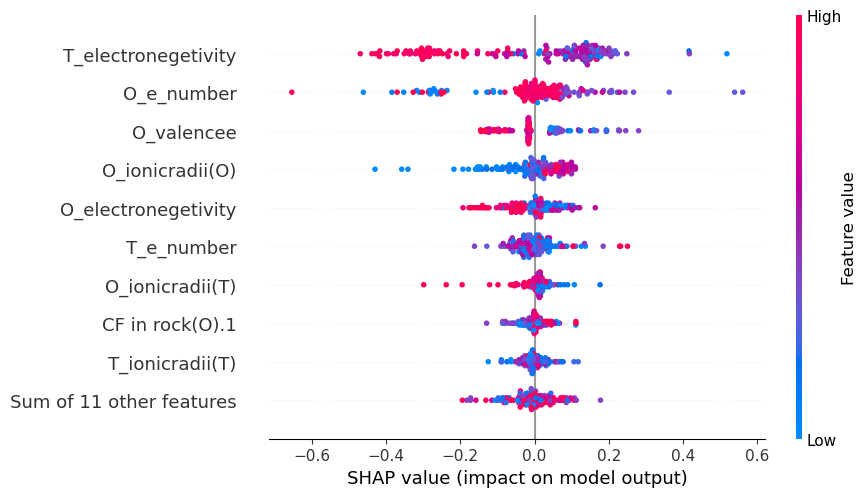

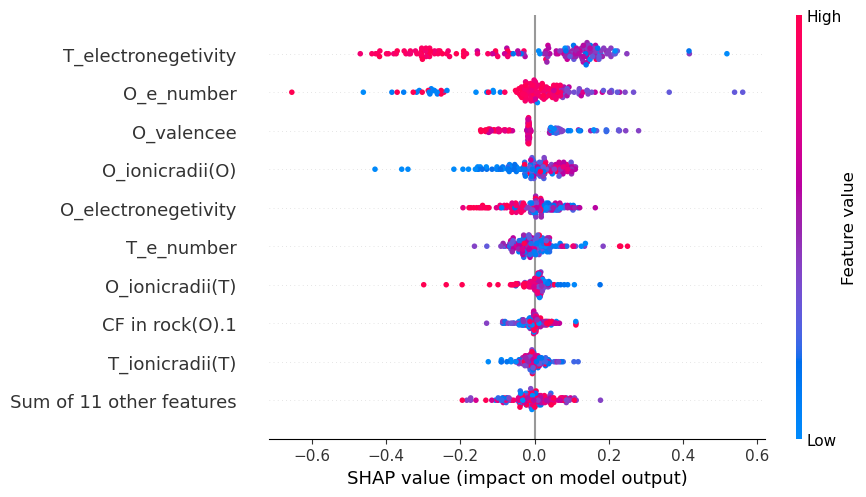

In [99]:
explainer = shap.Explainer(model_xgb,X)
SHAP_value = explainer(X)
shap.plots.beeswarm(SHAP_value)
fig = shap.plots.beeswarm(SHAP_value, show=False)
fig.figure.savefig("shap_beeswarm_highres_max.png", dpi=600, bbox_inches='tight')

In [101]:
Y2 = data['delta']

In [103]:
print(X.shape)
print(Y2.shape)

(157, 20)
(157,)


In [105]:
model_xgb2 = xgb.XGBRegressor(learning_rate=0.25, n_estimators=500)

In [107]:
model_xgb2.fit(X, Y2)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.25, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=None, num_parallel_tree=None, ...)

In [109]:
model_xgb2.feature_importances_

array([0.055126  , 0.14304775, 0.04991313, 0.0194655 , 0.        ,
       0.        , 0.02966989, 0.25703773, 0.00413518, 0.02955396,
       0.12167694, 0.04663135, 0.02520716, 0.02148809, 0.06513013,
       0.        , 0.07735426, 0.01347792, 0.03189197, 0.00919308],
      dtype=float32)

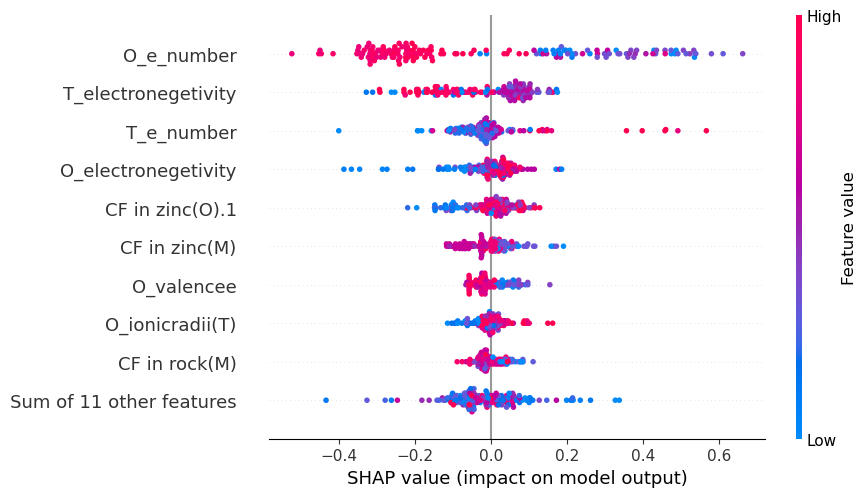

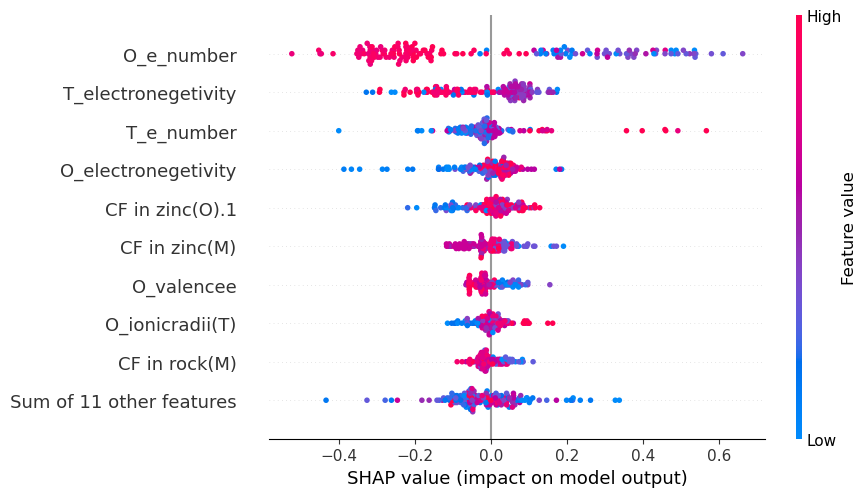

In [111]:
explainer2 = shap.Explainer(model_xgb2,X)
SHAP_value2 = explainer2(X)
shap.plots.beeswarm(SHAP_value2)
fig2 = shap.plots.beeswarm(SHAP_value2, show=False)
fig2.figure.savefig("shap_beeswarm_highres_delta.png", dpi=600, bbox_inches='tight')